## 实验：K 均值聚类

### 实验概要

K-Means 算法是一种简单的迭代型聚类算法，采用距离作为相似性指标，从而发现给定数据集中的 $K$ 个类，且每个类的中心是根据类中所有值的均值得到，每个类用聚类中心来描述。对于给定的一个包含 `N` 个 `D` 维数据点的数据集 `X`，以及要分开的类别数 $K$，选取欧氏距离作为相似度指标，聚类目标是使得各类的距离平方和最小，即最小化：

$$J = \sum_{k=1}^{k}\sum_{i=1}^{n}||x_i-u_k||^2$$

结合最小二乘法和拉格朗日原理，聚类质心为对应聚类中各数据点的平均值，同时为了使得算法收敛，在迭代过程中，应使最终的聚类质心尽可能的不变。

### 算法流程

K-Means 是一个反复迭代的过程，算法分为四个步骤：

1. 选取数据空间中的 K 个对象作为初始质心，每个对象代表一个聚类质心；
2. 对于样本中的数据对象，根据它们与这些聚类质心的欧氏距离，按距离最近的准则将它们分到距离它们最近的聚类质心（最相似）所对应的类；
3. 更新聚类质心：将每个类别中所有对象所对应的均值作为该类别的聚类质心，计算目标函数的值；
4. 判断聚类质心和目标函数的值是否发生改变，若不变，则输出结果，若改变，则返回 `2`）。

<img src="./img/IMG_0142.gif">

在 NLP 的场景下，假设你有 10 个文档，需要根据它们的属性 (包含的单词数、段落数、标点符号和文档的语气...) 将它们分成三类。在这种情况下，我们假设 $k$ 是 `3`，也就是说，我们要创建这三个组。首先，需要选择三个质心。在初始化阶段，这 10 个文档中的每一个都被分配到这三个类别中的一个，从而形成三个组。在更新阶段，计算三个新组成的组的质心。

#### K 值优化

另外，你也可以根据实际情况调整最终的集群数量，其中一种方法是利用畸变值 (每个类的畸变值等于该类的质心与其内部成员位置距离的平方和)。良好集群背后的理念是拥有较小的畸变值和少量的集群。畸变值随集群数量的增加而减小。所以，这是一个取舍。最佳实践是畸变图中的肘部点是一个很好的选择，因为在此之后畸变值的变化并不显著。

<img src="./img/Elbow Method.jpg" width="30%">

因此，为了确定最优的集群数 (即 $k$)，我们对不同的 $k$ 值执行 K-Means 聚类，并记录它们的误差平方和。我们试着为 $k$ 选择一个最小的值，它有最小的误差 (距离) 平方和。这种方法称为: **肘形法 (Elbow Method)**。

### 实验目标

### 1. 导入库

In [1]:
# 设置 nltk_data 路径环境变量
from nltk import data
data.path.append(r'../nltk_data')

from scipy.spatial.distance import cdist # 距离计算库
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns 
sns.set()

import re
import string

import nltk
from nltk import word_tokenize           # 分词
from nltk.corpus import stopwords        # 停用词
from nltk.stem import WordNetLemmatizer  # 词干提取

from sklearn.datasets import fetch_20newsgroups              # 加载分类数据
from sklearn.feature_extraction.text import TfidfVectorizer  # 计算TF-IDF
from sklearn.cluster import KMeans                           # k均值模型
from collections import Counter                              # 词频统计
from pylab import *

import warnings
warnings.filterwarnings('ignore')

### 2. 加载停用词

停用词包括 NLTK 加载的英文停用词，还包括 `string.printable` 可打印的字符串

In [2]:
stop_words = stopwords.words('english')
stop_words = stop_words + list(string.printable)
lemmatizer = WordNetLemmatizer()

### 3. 从本地加载数据

我们选择其中的 `['misc.forsale', 'sci.electronics', 'talk.religion.misc']` 数据进行加载：

In [3]:
categories= ['misc.forsale', 'sci.electronics', 'talk.religion.misc']

**注意：由于通过互联网下载速度很慢，我们直接通过本地加载 `fetch_20newsgroups` 数据集：**

In [4]:
news_data = fetch_20newsgroups(data_home='./data',               # 修改本地数据加载路径
                               subset='train',                   # 仅提取训练集
                               categories=categories,            # 提取指定的类别
                               shuffle=True,                     # 打乱顺序
                               random_state=42,                   # 随机种子
                               download_if_missing=False)         # 强制不通过互联网下载

`fetch_20newsgroups` 函数不仅仅负责从互联网上下载数据集，还包含了各种对数据集执行预处理等各种参数。

关于 `fetch_20newsgroups` 函数的更多选项，[请查阅官方文档](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html)

### 4. 生成 DataFrame

将文本数据和对应的分类标签组成 DataFrame 数组

In [5]:
news_data_df = pd.DataFrame({'text' : news_data['data'], 'category': news_data.target})

### 5. 文本清洗

对于文本数据做如下处理：

1. 使用正则表达式对文本进行切分并过滤掉一些特殊符号
2. 过滤停用词
3. 对过滤好的分词进行词干提取 (词形还原)

In [6]:
news_data_df['cleaned_text'] = news_data_df['text'].apply(\
lambda x : ' '.join([lemmatizer.lemmatize(word.lower()) \
    for word in word_tokenize(re.sub(r'([^\s\w]|_)+', ' ', str(x))) if word.lower() not in stop_words]))

### 6. 计算 TF-IDF

对处理好的分词进行 TF-IDF 的计算并提取出前 200 个关键词汇：

In [7]:
tfidf_model = TfidfVectorizer(max_features=200)
tfidf_df = pd.DataFrame(tfidf_model.fit_transform(news_data_df['cleaned_text']).todense())
tfidf_df.columns = sorted(tfidf_model.vocabulary_)
tfidf_df.head()

,00,10,100,12,14,15,16,20,25,30,...,well,wire,wiring,without,word,work,world,would,writes,year
0,0.435655,0.0,0.000000,0.0,0.000000,0.127775,0.136811,0.127551,0.133311,0.0,...,0.0,0.0,0.0,0.0,0.0,0.113042,0.000000,0.000000,0.000000,0.0
1,0.000000,0.0,0.000000,0.0,0.000000,0.294937,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0
2,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0
3,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.142267,0.106317,0.100306,0.0
4,0.000000,0.0,0.207003,0.0,0.191897,0.182138,0.000000,0.000000,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0


### 7. 建立 KMeans 模型

使用 `KMeans` 建立 k 均值聚类模型，聚类数量为 `4`：

In [8]:
kmeans = KMeans(n_clusters=4)        # 设置集群数量
kmeans.fit(tfidf_df)                 # 使用 fit 方法训练 tf-idf 向量化后的文本数据
y_kmeans = kmeans.predict(tfidf_df)
news_data_df['obtained_clusters'] = y_kmeans

### 8. 计算交叉表格

计算生成文本中 `category` 和 `obtained_clusters` 的简单交叉表格。

In [9]:
pd.crosstab(news_data_df['category'].replace({0:'misc.forsale', 1:'sci.electronics', 2:'talk.religion.misc'}),\
            news_data_df['obtained_clusters'].replace({0 : 'cluster_1', 1 : 'cluster_2', 2 : 'cluster_3', 3: 'cluster_4'}))

obtained_clusters,cluster_1,cluster_2,cluster_3,cluster_4
category,,,,
misc.forsale,356,1,95,133
sci.electronics,10,0,440,141
talk.religion.misc,0,220,84,73


从上图可以看出，集群二主要是 `talk.religion.misc` 相关的新闻，集群四主要是 `misc.forsale` 相关的新闻。其他两个集群现在有了适当的区别，但是集群三拥有大多数 `sci.electronics` 相关的新闻。

### 9. 肘形法 K 值优化

使用 **肘形法 (Elbow Method)** ，根据观察斜率变化，显示簇的最佳数目。设置蔟的范围为 `1-10`，并计算每次聚类的距离和：

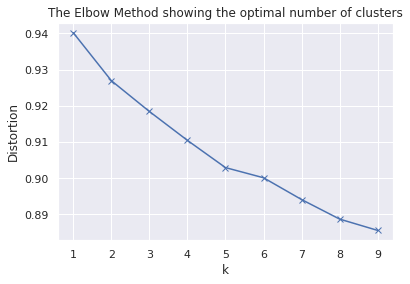

In [10]:
# 肘部法求最佳K值
distortions = []
K = range(1,10)
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(tfidf_df)
    distortions.append(sum(np.min(cdist(tfidf_df, kmeanModel.cluster_centers_, 'euclidean'),
                                  axis=1)) / tfidf_df.shape[0])
# 绘制肘部图形
plt.plot(K, distortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Distortion')
plt.title('The Elbow Method showing the optimal number of clusters')
plt.show()

从上面的图中，我们可以得出最优的集群数是 2。

<img src="./img/k2.png" width="50%">

### 实验小结

在本实验中，你实现了使用 K 均值聚类，对新闻文本数据进行无监督学习的集群分类。